<a href="https://colab.research.google.com/github/sardorbekmuminov/transfer-learning-project/blob/main/transfer_learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Image Classification with Transfer Learning

This project compares training ResNet18 from scratch,
feature extraction, and fine-tuning on the ImageWoof dataset.

Import Libraries

In [1]:
import urllib.request, zipfile, numpy as np, torch, torch.nn as nn
import torch.nn.functional as F, timm
from pathlib import Path
from PIL import Image

#Load Pretrained ResNet18
model = timm.create_model("resnet18", pretrained=True)
model.eval()
print(sum(p.numel() for p in model.parameters()))
print(model.fc)

model.safetensors: reconstructing file:   0%|          |  0.00B / 46.8MB            

model.safetensors: downloading bytes:           |  0.00B            

11689512
Linear(in_features=512, out_features=1000, bias=True)


In [2]:
torch.device = 'cuda' if torch.cuda.is_available() else 'cpu'
torch.device

'cuda'

In [3]:
#Prepare Image Preprocessing
mean = torch.tensor([0.485, 0.456, 0.406], device=torch.device).view(1, 3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225], device=torch.device).view(1, 3, 1, 1)

# cfg = model.pretrained_cfg
# print(cfg["mean"], cfg["std"])

prep = lambda xb: (xb.float() / 255 - mean) / std

BASE = "https://raw.githubusercontent.com/pytorch/vision/main/gallery/assets/dog1.jpg"
urllib.request.urlretrieve(BASE , "dog1.jpg")
img = Image.open("dog1.jpg").convert("RGB").resize((224, 224))
x = torch.tensor(np.asarray(img), device=torch.device, dtype=torch.float).permute(2, 0, 1).unsqueeze(0)
x.shape

# # Move model to the correct device
model = model.to(torch.device)

with torch.no_grad():
    p = model(prep(x)).softmax(1)[0]
info = timm.data.ImageNetInfo()
for v, i in zip(*p.topk(3)):
    print(info.index_to_description(int(i)), round(float(v), 5))

Pembroke, Pembroke Welsh corgi 0.8788
dingo, warrigal, warragal, Canis dingo 0.04282
Cardigan, Cardigan Welsh corgi 0.0288


In [4]:
URL = "https://github.com/ultralytics/assets/releases/download/v0.0.0/"
urllib.request.urlretrieve(URL + "imagewoof160.zip", "woof.zip")
zipfile.ZipFile("woof.zip").extractall(".")

root = Path("imagewoof160")
classes = sorted(p.name for p in (root / "train").iterdir())
print(len(classes), classes[:2])

10 ['n02086240', 'n02087394']


In [5]:
def load(split, per_class):
    X, y = [], []
    for c, name in enumerate(classes):
        for f in sorted((root / split / name).glob("*.JPEG"))[:per_class]:
            img = Image.open(f).convert("RGB").resize((128, 128))
            X.append(np.asarray(img))
            y.append(c)
    return torch.tensor(np.stack(X), device=torch.device).permute(0, 3, 1, 2), torch.tensor(y, device=torch.device)

Xtr, ytr = load("train", 200)
Xte, yte = load("val", 100)
print(Xtr.shape, Xte.shape)

torch.Size([2000, 3, 128, 128]) torch.Size([1000, 3, 128, 128])


In [6]:
torch.manual_seed(0)
perm = torch.randperm(10)
perm[8:10]

tensor([6, 2])

In [7]:
#Define Training and Evaluation Functions
def acc(m, X, y):
    m.eval()
    with torch.no_grad():
        out = [m(prep(X[i:i+100])) for i in range(0, len(X), 100)]
    return (torch.cat(out).argmax(1) == y).float().mean().item()

def train(m, params, epochs=5, lr=1e-3, bs=32):
    opt = torch.optim.Adam(params, lr=lr) #1
    accs = []
    for e in range(epochs):
        m.train()
        perm = torch.randperm(len(Xtr))
        for i in range(0, len(Xtr), bs):
            idx = perm[i:i+bs]
            loss = F.cross_entropy(m(prep(Xtr[idx])), ytr[idx]) #2
            opt.zero_grad(); #3
            loss.backward(); #4
            opt.step()       #5
        accs.append(acc(m, Xte, yte))
    return accs

In [8]:
nn.Linear(512, 10)

Linear(in_features=512, out_features=10, bias=True)

In [9]:
#Train from Scratch
torch.manual_seed(0)

scratch = timm.create_model("resnet18", pretrained=False, num_classes=10).to(torch.device)
res = {}
res["noldan"] = train(scratch, scratch.parameters())
print([round(a, 2) for a in res["noldan"]])

[0.21, 0.24, 0.21, 0.23, 0.28]


In [10]:
#Feature Extraction
bb = timm.create_model("resnet18", pretrained=True, num_classes=0).to(torch.device).eval()


def feats(X):
    with torch.no_grad():
        return torch.cat([bb(prep(X[i:i + 100])) for i in range(0, len(X), 100)])

Ftr, Fte = feats(Xtr), feats(Xte)
print(Ftr.shape)

torch.Size([2000, 512])


In [11]:
torch.manual_seed(0)

head = nn.Linear(512, 10).to(torch.device)

opt = torch.optim.Adam(head.parameters(), lr=1e-3)
accs = []
for e in range(50):
    perm = torch.randperm(len(Ftr))
    for i in range(0, len(Ftr), 32):
        idx = perm[i:i + 32]
        loss = F.cross_entropy(head(Ftr[idx]), ytr[idx])
        opt.zero_grad();
        loss.backward();
        opt.step()
    accs.append((head(Fte).argmax(1) == yte).float().mean().item())

res["feature extraction"] = accs
print(round(accs[-1], 3))

0.823


In [12]:
#Fine-tuning
torch.manual_seed(0)
model = timm.create_model("resnet18", pretrained=True, num_classes=10).to(torch.device)

res["fine-tuning"] = train(model, model.parameters(), lr=3e-4)
print([round(a, 2) for a in res["fine-tuning"]])

[0.61, 0.75, 0.77, 0.79, 0.8]


In [13]:
#Save the Model
torch.save(model.state_dict(), "model.pt")

In [14]:
# torch.manual_seed(0)
# frozen = timm.create_model("resnet18", pretrained=True, num_classes=10)
# for p in frozen.parameters():
#     p.requires_grad = False
# for p in frozen.fc.parameters():
#     p.requires_grad = True

# accs = train(frozen, frozen.fc.parameters())
# print("qotirilgan, train() bilan:", round(accs[-1], 3))

In [15]:
#Make Predictions
names = ["Shih-Tzu", "Ridgeback", "Beagle", "Foxhound", "Border terrier",
         "Aussie terrier", "Golden retriever", "Sheepdog", "Samoyed", "Dingo"]
idx = torch.arange(0, 1000, 100)
model.eval()
with torch.no_grad():
    pred = model(prep(Xte[idx])).argmax(1)
for p, t in zip(pred, yte[idx]):
    print(names[p], "|", names[t])

Shih-Tzu | Shih-Tzu
Ridgeback | Ridgeback
Beagle | Beagle
Golden retriever | Foxhound
Border terrier | Border terrier
Aussie terrier | Aussie terrier
Golden retriever | Golden retriever
Sheepdog | Sheepdog
Samoyed | Samoyed
Dingo | Dingo


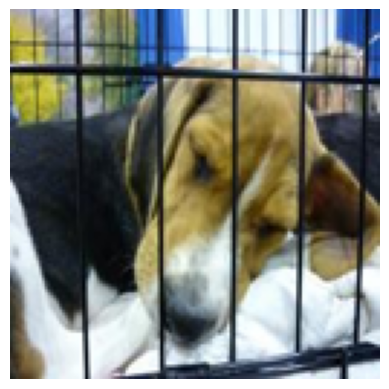

In [16]:
#Visualize Predictions
import matplotlib.pyplot as plt

# Move to CPU and permute to (Height, Width, Channels) for plotting
plt.imshow(Xte[300].cpu().permute(1, 2, 0))
plt.axis("off")
plt.show()

## 12. Conclusion

In this project, three approaches were explored:

- Training ResNet18 from scratch
- Feature extraction using a pretrained ResNet18
- Fine-tuning a pretrained ResNet18

The results help demonstrate the benefits of transfer learning
for image classification.

The best-performing approach can be identified by comparing
the final validation accuracy of each method.